#📊Data Understanding

##Import Libraries

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
import ast
import json

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Libraries imported successfully.")


Pandas: 2.3.3
NumPy: 2.2.6
Libraries imported successfully.


In [26]:

from google.colab import drive

drive.mount("/content/drive")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [27]:

DATA_DIR = Path("/content/drive/MyDrive/MovieMatch")

print("Folder exists:", DATA_DIR.exists())
print("\nFiles found:")

for file in DATA_DIR.iterdir():
    if file.is_file():
        print(f"{file.name}: {file.stat().st_size / (1024**2):.2f} MB")


Folder exists: True

Files found:
links.csv: 0.94 MB
movies_metadata.csv: 32.85 MB
ratings.csv: 676.68 MB


##Inspect files, columns, data types, rating scale, and dataset size.

In [28]:
ratings_path = DATA_DIR / "ratings.csv"
metadata_path = DATA_DIR / "movies_metadata.csv"
links_path = DATA_DIR / "links.csv"

ratings_sample = pd.read_csv(ratings_path, nrows=10)
metadata_sample = pd.read_csv(
    metadata_path, nrows=10, low_memory=False
)
links_sample = pd.read_csv(links_path, nrows=10)

print("RATINGS")
print("Columns:", ratings_sample.columns.tolist())
display(ratings_sample.head())

print("\nMOVIE METADATA")
print("Columns:", metadata_sample.columns.tolist())
display(metadata_sample.head())

print("\nLINKS")
print("Columns:", links_sample.columns.tolist())
display(links_sample.head())


RATINGS
Columns: ['userId', 'movieId', 'rating', 'timestamp']


,userId,movieId,rating,timestamp
0,1,110,1.0,1425941529
1,1,147,4.5,1425942435
2,1,858,5.0,1425941523
3,1,1221,5.0,1425941546
4,1,1246,5.0,1425941556



MOVIE METADATA
Columns: ['adult', 'belongs_to_collection', 'budget', 'genres', 'homepage', 'id', 'imdb_id', 'original_language', 'original_title', 'overview', 'popularity', 'poster_path', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'video', 'vote_average', 'vote_count']


,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",...,1995-10-30,373554033,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,...,1995-12-15,262797249,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,...,1995-12-22,0,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.5,92
3,False,NaN,16000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",NaN,31357,tt0114885,en,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",...,1995-12-22,81452156,127.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Friends are the people who let you be yourself...,Waiting to Exhale,False,6.1,34
4,False,"{'id': 96871, 'name': 'Father of the Bride Col...",0,"[{'id': 35, 'name': 'Comedy'}]",NaN,11862,tt0113041,en,Father of the Bride Part II,Just when George Banks has recovered from his ...,...,1995-02-10,76578911,106.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Just When His World Is Back To Normal... He's ...,Father of the Bride Part II,False,5.7,173



LINKS
Columns: ['movieId', 'imdbId', 'tmdbId']


,movieId,imdbId,tmdbId
0,1,114709,862
1,2,113497,8844
2,3,113228,15602
3,4,114885,31357
4,5,113041,11862


In [29]:
#display the first 10 user ratings
display(ratings_sample)

#Find the smallest and largest rating in this sample
print("Minimum rating:", ratings_sample["rating"].min())
print("Maximum rating:", ratings_sample["rating"].max())

#See which column we have
print("Columns", ratings_sample.columns.tolist())

,userId,movieId,rating,timestamp
0,1,110,1.0,1425941529
1,1,147,4.5,1425942435
2,1,858,5.0,1425941523
3,1,1221,5.0,1425941546
4,1,1246,5.0,1425941556
5,1,1968,4.0,1425942148
6,1,2762,4.5,1425941300
7,1,2918,5.0,1425941593
8,1,2959,4.0,1425941601
9,1,4226,4.0,1425942228


Minimum rating: 1.0
Maximum rating: 5.0
Columns ['userId', 'movieId', 'rating', 'timestamp']


In [30]:
# Inspect the rating column using the full dataset's schema
ratings_schema = pd.read_csv(ratings_path, nrows=0)
print("Column data types:")
print(ratings_schema.dtypes)

Column data types:
userId       object
movieId      object
rating       object
timestamp    object
dtype: object


In [31]:
# Read only the rating column to check its values.
# This uses much less memory than loading all four columns.
rating_values = pd.read_csv(
    ratings_path,
    usecols=["rating"]
)

print("\nNumber of rating records:", len(rating_values))
print("Missing ratings:", rating_values["rating"].isna().sum())
print("Minimum rating:", rating_values["rating"].min())
print("Maximum rating:", rating_values["rating"].max())
print("Number of unique rating values:", rating_values["rating"].nunique())
print("\nUnique rating values:")
print(sorted(rating_values["rating"].dropna().unique()))


Number of rating records: 26024289
Missing ratings: 0
Minimum rating: 0.5
Maximum rating: 5.0
Number of unique rating values: 10

Unique rating values:
[np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0)]


In [32]:

# Read a small sample so pandas can inspect actual values
ratings_check = pd.read_csv(ratings_path, nrows=1000)

print("Data types based on actual rows:")
print(ratings_check.dtypes)

print("\nMissing values in each column:")
print(ratings_check.isna().sum())

print("\nNumber of unique values in the sample:")
print(ratings_check.nunique())


Data types based on actual rows:
userId         int64
movieId        int64
rating       float64
timestamp      int64
dtype: object

Missing values in each column:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Number of unique values in the sample:
userId        15
movieId      775
rating        10
timestamp    721
dtype: int64


In [39]:

# Read only the columns needed for catalogue coverage
metadata_columns = pd.read_csv(
    metadata_path,
    nrows=0
).columns.tolist()

print("Available metadata columns:")
print(metadata_columns)

# Load the relevant metadata fields
movies_info = pd.read_csv(
    metadata_path,
    usecols=["id", "title", "release_date", "genres", "overview"],
    low_memory=False
)

print("\nNumber of metadata rows:", len(movies_info))

print("\nData types:")
print(movies_info.dtypes)

print("\nFirst five movies:")
display(movies_info.head())


Available metadata columns:
['adult', 'belongs_to_collection', 'budget', 'genres', 'homepage', 'id', 'imdb_id', 'original_language', 'original_title', 'overview', 'popularity', 'poster_path', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'video', 'vote_average', 'vote_count']

Number of metadata rows: 45466

Data types:
genres          object
id              object
overview        object
release_date    object
title           object
dtype: object

First five movies:


,genres,id,overview,release_date,title
0,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",862,"Led by Woody, Andy's toys live happily in his ...",1995-10-30,Toy Story
1,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",8844,When siblings Judy and Peter discover an encha...,1995-12-15,Jumanji
2,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",15602,A family wedding reignites the ancient feud be...,1995-12-22,Grumpier Old Men
3,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",31357,"Cheated on, mistreated and stepped on, the wom...",1995-12-22,Waiting to Exhale
4,"[{'id': 35, 'name': 'Comedy'}]",11862,Just when George Banks has recovered from his ...,1995-02-10,Father of the Bride Part II


In [34]:


# Read the ID mapping file
links = pd.read_csv(links_path)

print("Number of rows in links.csv:", len(links))

print("\nColumn data types:")
print(links.dtypes)

print("\nMissing values:")
print(links.isna().sum())

print("\nFirst five mappings:")
display(links.head())

print("\nDuplicate MovieLens IDs:", links["movieId"].duplicated().sum())
print("Duplicate TMDB IDs:", links["tmdbId"].dropna().duplicated().sum())



Number of rows in links.csv: 45843

Column data types:
movieId      int64
imdbId       int64
tmdbId     float64
dtype: object

Missing values:
movieId      0
imdbId       0
tmdbId     219
dtype: int64

First five mappings:


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0



Duplicate MovieLens IDs: 0
Duplicate TMDB IDs: 30


In [35]:

# Compare the IDs for one example movie
example = links.loc[links["movieId"] == 1]

print(example)
print("\nMovieLens ID:", example["movieId"].iloc[0])
print("TMDB ID:", example["tmdbId"].iloc[0])


   movieId  imdbId  tmdbId
0        1  114709   862.0

MovieLens ID: 1
TMDB ID: 862.0


In [44]:

# Convert IDs to numeric values.
# Invalid values become NaN instead of causing an error.
links["tmdbId_num"] = pd.to_numeric(
    links["tmdbId"], errors="coerce"
)

movies_info["id_num"] = pd.to_numeric(
    movies_info["id"], errors="coerce"
)

# Count IDs that could be converted successfully.
print("Valid numeric TMDB IDs in links:",
      links["tmdbId_num"].notna().sum())

print("Valid numeric IDs in metadata:",
      movies_info["id_num"].notna().sum())


Valid numeric TMDB IDs in links: 45624
Valid numeric IDs in metadata: 45463


In [37]:

# Get the unique, non-missing IDs from each file.
link_tmdb_ids = set(links["tmdbId_num"].dropna())
metadata_tmdb_ids = set(movies_info["id_num"].dropna())

# Find IDs that occur in both sets.
matching_ids = link_tmdb_ids.intersection(metadata_tmdb_ids)

print("Unique numeric TMDB IDs in links:",
      len(link_tmdb_ids))

print("Unique numeric IDs in metadata:",
      len(metadata_tmdb_ids))

print("IDs present in both files:",
      len(matching_ids))

print("IDs in links but not metadata:",
      len(link_tmdb_ids - metadata_tmdb_ids))

print("IDs in metadata but not links:",
      len(metadata_tmdb_ids - link_tmdb_ids))


Unique numeric TMDB IDs in links: 45594
Unique numeric IDs in metadata: 45433
IDs present in both files: 45433
IDs in links but not metadata: 161
IDs in metadata but not links: 0


In [40]:

# Convert release_date to a proper datetime value.
# Invalid or missing dates will become NaT.
movies_info["release_date_parsed"] = pd.to_datetime(
    movies_info["release_date"],
    errors="coerce"
)

# Extract the release year.
movies_info["release_year"] = (
    movies_info["release_date_parsed"].dt.year
)

print("Total metadata rows:", len(movies_info))

print("Rows with valid release dates:",
      movies_info["release_date_parsed"].notna().sum())

print("Rows without valid release dates:",
      movies_info["release_date_parsed"].isna().sum())

print("Rows released in 2010 or later:",
      (movies_info["release_year"] >= 2010).sum())

print("Rows from 2010 onward with an overview:",
      (
          (movies_info["release_year"] >= 2010)
          & movies_info["overview"].notna()
          & movies_info["overview"].str.strip().ne("")
      ).sum())


Total metadata rows: 45466
Rows with valid release dates: 45376
Rows without valid release dates: 90
Rows released in 2010 or later: 12800
Rows from 2010 onward with an overview: 12504


In [43]:

# Check whether the genres field is missing or empty.
genres_missing = movies_info["genres"].isna()

genres_empty = (
    movies_info["genres"].astype(str).str.strip().isin(["", "[]"])
)

recent_movies = movies_info["release_year"] >= 2010

print("Recent-release rows:", recent_movies.sum())

print("Recent rows with missing genres:",
      (recent_movies & genres_missing).sum())

print("Recent rows with empty genres:",
      (recent_movies & genres_empty).sum())

print("Recent rows with non-empty genres:",
      (recent_movies & ~genres_missing & ~genres_empty).sum())


Recent-release rows: 12800
Recent rows with missing genres: 0
Recent rows with empty genres: 532
Recent rows with non-empty genres: 12268


In [46]:

# Select recent movies with valid numeric TMDB IDs
recent_metadata = movies_info.loc[
    (movies_info["release_year"] >= 2010)
    & movies_info["id_num"].notna()
].copy()

# Connect metadata to the ID mapping
recent_with_links = recent_metadata.merge(
    links[["movieId", "tmdbId_num"]],
    left_on="id_num",
    right_on="tmdbId_num",
    how="inner"
)

print("Recent metadata rows with valid IDs:",
      len(recent_metadata))

print("Rows matched to links.csv:",
      len(recent_with_links))

print("Unique MovieLens movie IDs matched:",
      recent_with_links["movieId"].nunique())

display(
    recent_with_links[
        ["title", "release_year", "id_num", "movieId"]
    ].head(10)
)


Recent metadata rows with valid IDs: 12800
Rows matched to links.csv: 12812
Unique MovieLens movie IDs matched: 12800


,title,release_year,id_num,movieId
0,Venice,2010.0,79782.0,895
1,The Sleepover,2013.0,141210.0,1115
2,The Farmer's Wife,2012.0,143750.0,2223
3,A Place at the Table,2012.0,84198.0,2679
4,A Place at the Table,2012.0,84198.0,103208
5,Romance,2012.0,171982.0,2894
6,Kingdom Come,2011.0,136558.0,4249
7,Camille Claudel 1915,2013.0,110428.0,4484
8,Camille Claudel 1915,2013.0,110428.0,112062
9,My Kingdom,2011.0,78022.0,5904


In [47]:

# Find TMDB IDs that occur more than once in links.csv
duplicate_tmdb = links.loc[
    links["tmdbId_num"].notna()
    & links["tmdbId_num"].duplicated(keep=False)
].sort_values("tmdbId_num")

print("Rows involved in repeated TMDB IDs:",
      len(duplicate_tmdb))

display(duplicate_tmdb)


Rows involved in repeated TMDB IDs: 59


,movieId,imdbId,tmdbId,tmdbId_num
5905,6003,290538,4912.0,4912.0
34144,144606,270288,4912.0,4912.0
9215,27136,165303,5511.0,5511.0
7388,7587,62229,5511.0,5511.0
45197,174533,235679,10991.0,10991.0
4148,4241,266860,10991.0,10991.0
14089,70545,848281,11115.0,11115.0
25138,116752,446676,11115.0,11115.0
45202,174543,287635,12600.0,12600.0
5574,5672,313487,12600.0,12600.0


In [48]:

# Count how many times each TMDB ID appears in links.csv
tmdb_counts = (
    links.loc[links["tmdbId_num"].notna(), "tmdbId_num"]
    .value_counts()
)

# Keep only TMDB IDs that appear more than once
repeated_tmdb_ids = tmdb_counts[tmdb_counts > 1].index

# Find repeated mappings that match our recent metadata
recent_duplicate_matches = recent_metadata.loc[
    recent_metadata["id_num"].isin(repeated_tmdb_ids)
].merge(
    duplicate_tmdb[["movieId", "tmdbId_num"]],
    left_on="id_num",
    right_on="tmdbId_num",
    how="inner"
)

print("Recent metadata rows affected by repeated TMDB IDs:",
      len(recent_duplicate_matches))

display(
    recent_duplicate_matches[
        ["title", "release_year", "id_num", "movieId"]
    ].sort_values("id_num")
)


Recent metadata rows affected by repeated TMDB IDs: 24


,title,release_year,id_num,movieId
5,Black Gold,2011.0,77221.0,102174
4,Black Gold,2011.0,77221.0,47237
9,Black Gold,2011.0,77221.0,102174
8,Black Gold,2011.0,77221.0,47237
11,A Place at the Table,2012.0,84198.0,2679
10,A Place at the Table,2012.0,84198.0,103208
0,A Place at the Table,2012.0,84198.0,103208
1,A Place at the Table,2012.0,84198.0,2679
15,Camille Claudel 1915,2013.0,110428.0,112062
14,Camille Claudel 1915,2013.0,110428.0,4484


In [49]:

# Take the MovieLens IDs involved in repeated TMDB mappings
duplicate_movie_ids = duplicate_tmdb["movieId"].unique()

print("Distinct MovieLens IDs in repeated mappings:",
      len(duplicate_movie_ids))

# Read only the ratings for those IDs, in chunks.
# This avoids loading the full 676 MB ratings file into memory.
duplicate_ratings = []

for chunk in pd.read_csv(
    ratings_path,
    usecols=["userId", "movieId", "rating", "timestamp"],
    chunksize=500_000
):
    matched = chunk[chunk["movieId"].isin(duplicate_movie_ids)]

    if not matched.empty:
        duplicate_ratings.append(matched)

if duplicate_ratings:
    duplicate_ratings = pd.concat(duplicate_ratings, ignore_index=True)
else:
    duplicate_ratings = pd.DataFrame(
        columns=["userId", "movieId", "rating", "timestamp"]
    )

print("Rating records for these IDs:", len(duplicate_ratings))
print("Users represented:", duplicate_ratings["userId"].nunique())
print("MovieLens IDs with ratings:",
      duplicate_ratings["movieId"].nunique())


Distinct MovieLens IDs in repeated mappings: 59
Rating records for these IDs: 9453
Users represented: 7456
MovieLens IDs with ratings: 59


In [50]:

# Map each rating's MovieLens ID to its TMDB ID
duplicate_ratings_mapped = duplicate_ratings.merge(
    duplicate_tmdb[["movieId", "tmdbId_num"]].drop_duplicates(),
    on="movieId",
    how="left"
)

# Find repeated ratings by the same user for the same TMDB movie
repeated_user_movie = duplicate_ratings_mapped[
    duplicate_ratings_mapped.duplicated(
        subset=["userId", "tmdbId_num"],
        keep=False
    )
].sort_values(["userId", "tmdbId_num", "timestamp"])

print("Rating rows involved in repeated user-TMDB pairs:",
      len(repeated_user_movie))

print("Distinct user-TMDB pairs affected:",
      repeated_user_movie[["userId", "tmdbId_num"]]
      .drop_duplicates().shape[0])

display(repeated_user_movie.head(20))


Rating rows involved in repeated user-TMDB pairs: 250
Distinct user-TMDB pairs affected: 125


,userId,movieId,rating,timestamp,tmdbId_num
16,741,27528,4.0,1383705638,23305.0
15,741,8795,4.0,1384058958,23305.0
105,3519,6003,4.0,1454809222,4912.0
106,3519,144606,5.0,1455403396,4912.0
165,4916,5264,2.5,1435466977,15028.0
166,4916,144426,2.5,1445090302,15028.0
285,8287,6003,3.5,1460444571,4912.0
286,8287,144606,4.5,1460660114,4912.0
296,8622,6003,5.0,1452831245,4912.0
297,8622,144606,4.0,1453091322,4912.0


In [51]:

# 1. Find TMDB IDs that map to multiple MovieLens IDs
recent_tmdb_counts = (
    recent_with_links.groupby("id_num")["movieId"]
    .nunique()
)

repeated_recent_tmdb_ids = recent_tmdb_counts[
    recent_tmdb_counts > 1
].index

print("Recent TMDB movies with multiple MovieLens IDs:",
      len(repeated_recent_tmdb_ids))

# 2. Inspect the affected movies and their MovieLens IDs
recent_mapping_issues = recent_with_links[
    recent_with_links["id_num"].isin(repeated_recent_tmdb_ids)
].sort_values(["id_num", "movieId"])

print("Rows in affected recent mappings:",
      len(recent_mapping_issues))

display(
    recent_mapping_issues[
        ["title", "release_year", "id_num", "movieId"]
    ]
)


Recent TMDB movies with multiple MovieLens IDs: 6
Rows in affected recent mappings: 24


,title,release_year,id_num,movieId
11,Black Gold,2011.0,77221.0,47237
2069,Black Gold,2011.0,77221.0,47237
12,Black Gold,2011.0,77221.0,102174
2070,Black Gold,2011.0,77221.0,102174
3,A Place at the Table,2012.0,84198.0,2679
2199,A Place at the Table,2012.0,84198.0,2679
4,A Place at the Table,2012.0,84198.0,103208
2200,A Place at the Table,2012.0,84198.0,103208
7,Camille Claudel 1915,2013.0,110428.0,4484
3376,Camille Claudel 1915,2013.0,110428.0,4484


In [52]:

# MovieLens IDs involved in repeated mappings for 2010+ movies
recent_duplicate_movie_ids = (
    recent_mapping_issues["movieId"].unique()
)

# Store only rating records for these MovieLens IDs
recent_duplicate_rating_chunks = []

for chunk in pd.read_csv(
    ratings_path,
    usecols=["userId", "movieId", "rating", "timestamp"],
    chunksize=500_000
):
    matched = chunk[
        chunk["movieId"].isin(recent_duplicate_movie_ids)
    ]

    if not matched.empty:
        recent_duplicate_rating_chunks.append(matched)

# Combine the small matching subsets
if recent_duplicate_rating_chunks:
    recent_duplicate_ratings = pd.concat(
        recent_duplicate_rating_chunks,
        ignore_index=True
    )
else:
    recent_duplicate_ratings = pd.DataFrame(
        columns=["userId", "movieId", "rating", "timestamp"]
    )

print("Rating records for affected MovieLens IDs:",
      len(recent_duplicate_ratings))

print("Unique users who rated affected IDs:",
      recent_duplicate_ratings["userId"].nunique())

print("Unique MovieLens IDs with ratings:",
      recent_duplicate_ratings["movieId"].nunique())

display(recent_duplicate_ratings.head(10))


Rating records for affected MovieLens IDs: 893
Unique users who rated affected IDs: 823
Unique MovieLens IDs with ratings: 12


,userId,movieId,rating,timestamp
0,483,4484,3.5,1095879875
1,741,105769,4.0,1465112841
2,1572,105769,3.0,1453494147
3,2422,105769,2.5,1488008091
4,2998,4484,3.0,1096109677
5,3626,2679,4.0,1009100256
6,3777,114342,5.0,1489358284
7,3780,4484,3.0,1004715508
8,4269,4484,5.0,1002180558
9,4317,4484,3.0,1055499589


In [53]:

# Map each MovieLens ID to its actual TMDB movie
recent_id_mapping = (
    recent_mapping_issues[
        ["movieId", "id_num", "title", "release_year"]
    ]
    .drop_duplicates(subset=["movieId"])
)

# Attach the actual movie identity to each rating
recent_ratings_with_tmdb = recent_duplicate_ratings.merge(
    recent_id_mapping,
    on="movieId",
    how="inner"
)

# Find cases where the same user rated the same TMDB movie
# through multiple MovieLens IDs
duplicate_user_movie = (
    recent_ratings_with_tmdb
    .groupby(["userId", "id_num"])
    .filter(lambda group: group["movieId"].nunique() > 1)
    .sort_values(["userId", "id_num", "timestamp"])
)

print(
    "Rating records involved in duplicate user-movie ratings:",
    len(duplicate_user_movie)
)

print(
    "Distinct user-movie combinations affected:",
    duplicate_user_movie[["userId", "id_num"]]
    .drop_duplicates()
    .shape[0]
)

print(
    "Distinct users affected:",
    duplicate_user_movie["userId"].nunique()
)

display(
    duplicate_user_movie[
        ["userId", "title", "id_num", "movieId", "rating", "timestamp"]
    ].head(20)
)


Rating records involved in duplicate user-movie ratings: 18
Distinct user-movie combinations affected: 9
Distinct users affected: 7


,userId,title,id_num,movieId,rating,timestamp
131,45811,A Place at the Table,84198.0,2679,3.0,1493649411
134,45811,A Place at the Table,84198.0,103208,3.0,1499338522
132,45811,Camille Claudel 1915,110428.0,4484,5.0,1455271813
136,45811,Camille Claudel 1915,110428.0,112062,4.0,1455271836
138,45811,Cemetery of Splendour,298721.0,142861,5.0,1455977649
139,45811,Cemetery of Splendour,298721.0,162632,3.5,1473241811
393,121561,Cemetery of Splendour,298721.0,142861,3.0,1470961257
394,121561,Cemetery of Splendour,298721.0,162632,3.5,1473241660
502,152682,Camille Claudel 1915,110428.0,4484,3.5,1477845337
504,152682,Camille Claudel 1915,110428.0,112062,4.0,1493591219


#Exploratory Data Analysis

In [54]:

# Get the MovieLens IDs for movies released in 2010 or later.
recent_movie_ids = recent_with_links["movieId"].unique()

print("Unique MovieLens IDs in our recent-movie catalogue:",
      len(recent_movie_ids))


Unique MovieLens IDs in our recent-movie catalogue: 12800


Rating distribution for movies released in 2010 or later:


,count
0.5,45016
1.0,38911
1.5,37823
2.0,92795
2.5,132459
3.0,291717
3.5,352095
4.0,457011
4.5,231442
5.0,234048


Total ratings in the selected catalogue: 1913317


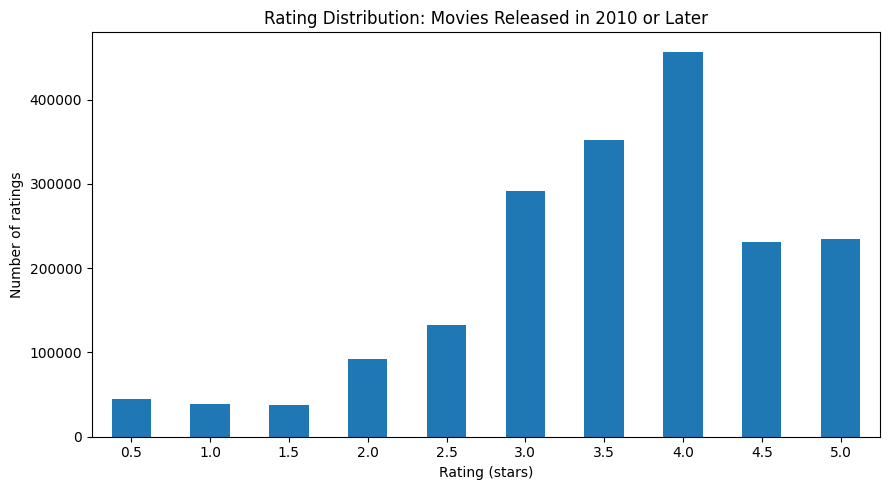

In [56]:

# Count ratings only for movies in our selected catalogue.
recent_rating_counts = {}

for chunk in pd.read_csv(
    ratings_path,
    usecols=["movieId", "rating"],
    chunksize=500_000
):
    # Keep ratings for our eligible movies only.
    filtered = chunk[chunk["movieId"].isin(recent_movie_ids)]

    # Count how often each rating value occurs.
    counts = filtered["rating"].value_counts()

    for rating, count in counts.items():
        recent_rating_counts[rating] = (
            recent_rating_counts.get(rating, 0) + count
        )

# Arrange the results in rating order.
rating_distribution = pd.Series(
    recent_rating_counts,
    name="count"
).sort_index()

print("Rating distribution for movies released in 2010 or later:")
display(rating_distribution.to_frame())

print("Total ratings in the selected catalogue:",
      int(rating_distribution.sum()))

plt.figure(figsize=(9, 5))

rating_distribution.plot(kind="bar")

plt.title("Rating Distribution: Movies Released in 2010 or Later")
plt.xlabel("Rating (stars)")
plt.ylabel("Number of ratings")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()



Movies with at least one rating: 12658

Summary of ratings per movie:


,rating_count
count,12658.000000
mean,151.154764
std,866.545222
min,1.000000
25%,2.000000
50%,6.000000
75%,25.000000
max,35297.000000



Top 10 movies by number of ratings:


,rating_count
79132,35297
109487,18693
99114,16985
91529,16386
74458,15531
89745,14967
81845,13075
116797,12939
78499,12874
134130,12662


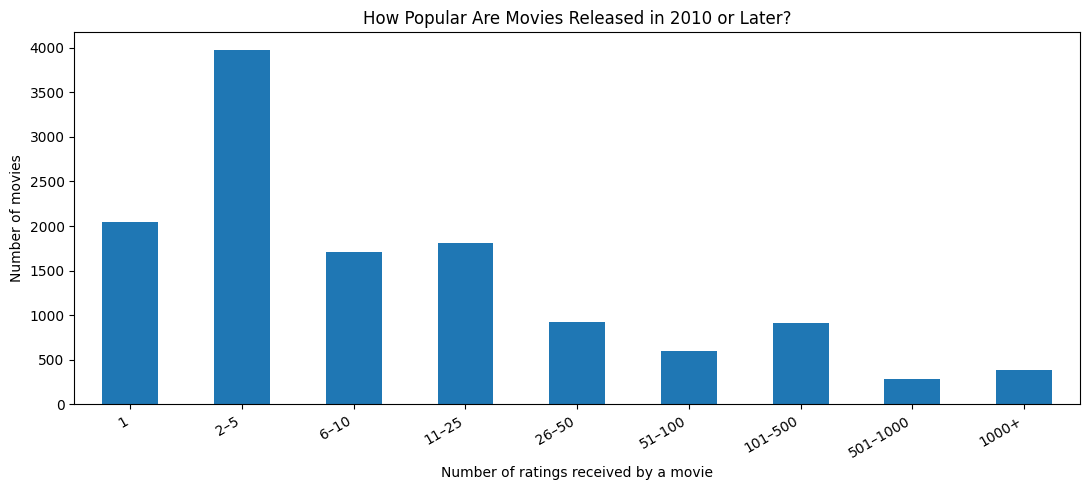

,Number of movies
rating_count,
1,2043
2–5,3973
6–10,1712
11–25,1815
26–50,920
51–100,602
101–500,918
501–1000,288
1000+,387


In [62]:

# Count ratings received by each eligible movie.
# This uses the full ratings file in chunks.

movie_rating_counts = {}

for chunk in pd.read_csv(
    ratings_path,
    usecols=["movieId"],
    chunksize=500_000
):
    filtered = chunk[
        chunk["movieId"].isin(recent_movie_ids)
    ]

    counts = filtered["movieId"].value_counts()

    for movie_id, count in counts.items():
        movie_rating_counts[movie_id] = (
            movie_rating_counts.get(movie_id, 0) + count
        )

movie_popularity = pd.Series(
    movie_rating_counts,
    name="rating_count"
).sort_values(ascending=False)

print("Movies with at least one rating:",
      len(movie_popularity))

print("\nSummary of ratings per movie:")
display(movie_popularity.describe().to_frame())

print("\nTop 10 movies by number of ratings:")
display(movie_popularity.head(10).to_frame())

print("\n")

# Group movies by their number of ratings.
bins = [0, 1, 5, 10, 25, 50, 100, 500, 1000, float("inf")]

labels = [
    "1",
    "2–5",
    "6–10",
    "11–25",
    "26–50",
    "51–100",
    "101–500",
    "501–1000",
    "1000+"
]

popularity_groups = pd.cut(
    movie_popularity,
    bins=bins,
    labels=labels,
    include_lowest=True
)

group_counts = popularity_groups.value_counts(
    sort=False
)

plt.figure(figsize=(11, 5))
group_counts.plot(kind="bar")

plt.title("How Popular Are Movies Released in 2010 or Later?")
plt.xlabel("Number of ratings received by a movie")
plt.ylabel("Number of movies")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

display(group_counts.rename("Number of movies").to_frame())


In [63]:

# Count how many eligible movie ratings each user has given.
user_rating_counts = {}

for chunk in pd.read_csv(
    ratings_path,
    usecols=["userId", "movieId"],
    chunksize=500_000
):
    # Keep only ratings for movies in our 2010+ catalogue.
    filtered = chunk[
        chunk["movieId"].isin(recent_movie_ids)
    ]

    counts = filtered["userId"].value_counts()

    for user_id, count in counts.items():
        user_rating_counts[user_id] = (
            user_rating_counts.get(user_id, 0) + count
        )

user_activity = pd.Series(
    user_rating_counts,
    name="ratings_per_user"
)

print("Users with at least one eligible rating:",
      len(user_activity))

print("\nSummary of ratings per user:")
display(user_activity.describe().to_frame())

print("\nNumber of users with fewer than 5 ratings:",
      (user_activity < 5).sum())

print("Number of users with at least 10 ratings:",
      (user_activity >= 10).sum())

print("Number of users with at least 20 ratings:",
      (user_activity >= 20).sum())


Users with at least one eligible rating: 67167

Summary of ratings per user:


,ratings_per_user
count,67167.000000
mean,28.485968
std,66.500218
min,1.000000
25%,3.000000
50%,8.000000
75%,26.000000
max,5297.000000



Number of users with fewer than 5 ratings: 24899
Number of users with at least 10 ratings: 30728
Number of users with at least 20 ratings: 20457


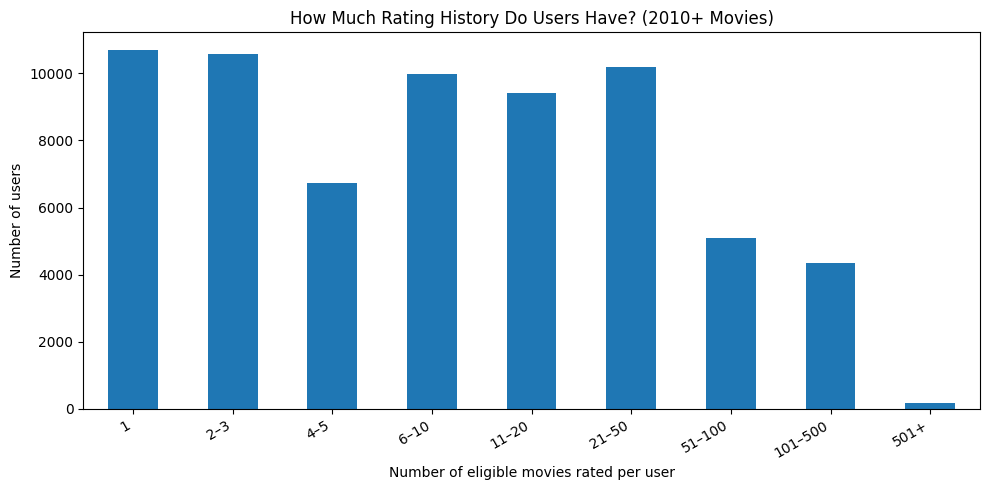

,Number of users
ratings_per_user,
1,10689
2–3,10565
4–5,6740
6–10,9979
11–20,9403
21–50,10178
51–100,5092
101–500,4348
501+,173


In [65]:

# Group users by the number of eligible movies they rated.
bins = [0, 1, 3, 5, 10, 20, 50, 100, 500, float("inf")]

labels = [
    "1",
    "2–3",
    "4–5",
    "6–10",
    "11–20",
    "21–50",
    "51–100",
    "101–500",
    "501+"
]

user_groups = pd.cut(
    user_activity,
    bins=bins,
    labels=labels,
    include_lowest=True
)

group_counts = user_groups.value_counts(sort=False)

plt.figure(figsize=(10, 5))
group_counts.plot(kind="bar")

plt.title("How Much Rating History Do Users Have? (2010+ Movies)")
plt.xlabel("Number of eligible movies rated per user")
plt.ylabel("Number of users")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

display(group_counts.rename("Number of users").to_frame())


In [66]:

# Number of unique users in our selected catalogue.
n_users = len(user_activity)

# Number of movies with at least one rating.
n_movies = len(movie_popularity)

# Number of observed user-movie rating records.
n_ratings = int(movie_popularity.sum())

# Total possible user-movie combinations.
total_possible = n_users * n_movies

# Percentage of combinations that have no rating.
sparsity = (1 - n_ratings / total_possible) * 100

print("Unique users:", n_users)
print("Movies with ratings:", n_movies)
print("Observed ratings:", n_ratings)
print("Possible user-movie combinations:", total_possible)
print(f"Rating matrix sparsity: {sparsity:.4f}%")
print(f"Matrix density: {100 - sparsity:.4f}%")


Unique users: 67167
Movies with ratings: 12658
Observed ratings: 1913317
Possible user-movie combinations: 850199886
Rating matrix sparsity: 99.7750%
Matrix density: 0.2250%


In [67]:

from collections import Counter

genre_counts = Counter()

for genre_text in recent_metadata["genres"].dropna():
    try:
        genres = ast.literal_eval(genre_text)

        if isinstance(genres, list):
            for genre in genres:
                if isinstance(genre, dict) and "name" in genre:
                    genre_counts[genre["name"]] += 1

    except (ValueError, SyntaxError):
        continue

genre_summary = (
    pd.DataFrame(
        genre_counts.items(),
        columns=["genre", "movie_count"]
    )
    .sort_values("movie_count", ascending=False)
    .reset_index(drop=True)
)

display(genre_summary.head(15))


,genre,movie_count
0,Drama,5183
1,Comedy,3537
2,Thriller,2363
3,Documentary,1883
4,Action,1617
5,Romance,1448
6,Horror,1370
7,Crime,929
8,Science Fiction,799
9,Adventure,785


,release_year,movie_count
0,2010,1501
1,2011,1667
2,2012,1722
3,2013,1889
4,2014,1974
5,2015,1905
6,2016,1604
7,2017,532
8,2018,5
9,2020,1


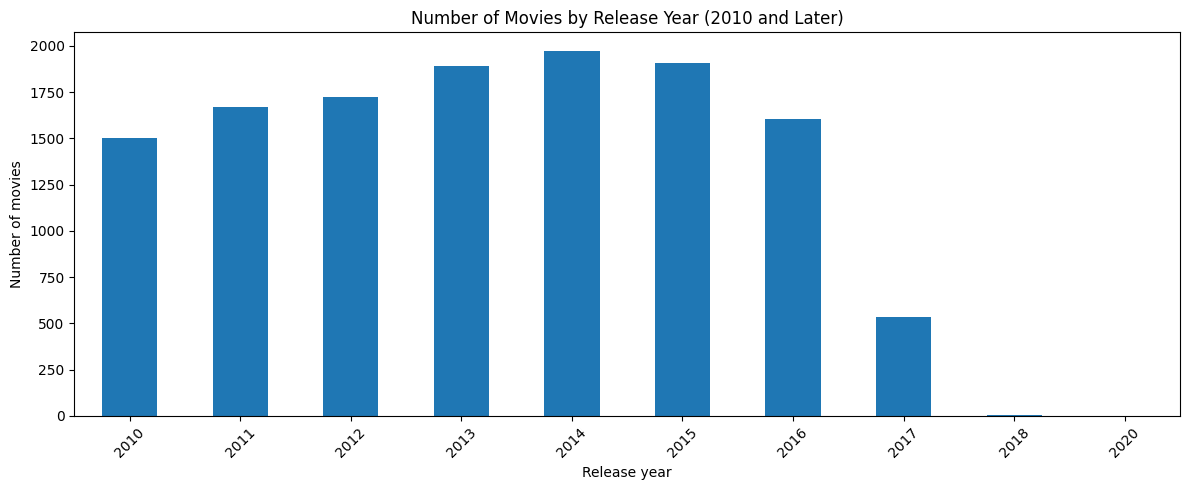

In [68]:

year_counts = (
    recent_metadata["release_year"]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

display(
    year_counts.rename("movie_count")
    .reset_index()
    .rename(columns={"index": "release_year"})
)

plt.figure(figsize=(12, 5))
year_counts.plot(kind="bar")

plt.title("Number of Movies by Release Year (2010 and Later)")
plt.xlabel("Release year")
plt.ylabel("Number of movies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


#Data Cleaning

In [80]:

# Build the mapping for the entire selected movie catalogue.
catalogue_mapping = (
    recent_with_links[
        ["movieId", "id_num", "title", "release_year"]
    ]
    .drop_duplicates(subset=["movieId", "id_num"])
    .copy()
)

print("Rows in catalogue mapping:", len(catalogue_mapping))
print("Unique MovieLens IDs:", catalogue_mapping["movieId"].nunique())
print("Unique TMDB IDs:", catalogue_mapping["id_num"].nunique())
print("Missing MovieLens IDs:", catalogue_mapping["movieId"].isna().sum())
print("Missing TMDB IDs:", catalogue_mapping["id_num"].isna().sum())



Rows in catalogue mapping: 12800
Unique MovieLens IDs: 12800
Unique TMDB IDs: 12794
Missing MovieLens IDs: 0
Missing TMDB IDs: 0


In [82]:

# Count how many distinct TMDB IDs each MovieLens ID maps to.
tmdb_ids_per_movie = catalogue_mapping.groupby("movieId")["id_num"].nunique()

# Identify MovieLens IDs associated with multiple TMDB IDs.
conflicting_movie_ids = tmdb_ids_per_movie[tmdb_ids_per_movie > 1]

print("MovieLens IDs mapping to multiple TMDB IDs:",
      len(conflicting_movie_ids))

print(conflicting_movie_ids)



MovieLens IDs mapping to multiple TMDB IDs: 0
Series([], Name: id_num, dtype: int64)


In [83]:

# Count distinct MovieLens IDs associated with each TMDB ID.
movie_ids_per_tmdb = (
    catalogue_mapping.groupby("id_num")["movieId"].nunique()
)

# Find TMDB IDs linked to multiple MovieLens IDs.
duplicate_tmdb_ids = movie_ids_per_tmdb[movie_ids_per_tmdb > 1]

print("TMDB IDs linked to multiple MovieLens IDs:",
      len(duplicate_tmdb_ids))

print(duplicate_tmdb_ids)


TMDB IDs linked to multiple MovieLens IDs: 6
id_num
77221.0     2
84198.0     2
110428.0    2
152795.0    2
265189.0    2
298721.0    2
Name: movieId, dtype: int64


In [84]:

# Display all mappings involved in the six duplicate-TMDB cases.
duplicate_movie_mapping = (
    catalogue_mapping[
        catalogue_mapping["id_num"].isin(duplicate_tmdb_ids.index)
    ]
    .sort_values(["id_num", "movieId"])
    .reset_index(drop=True)
)

display(duplicate_movie_mapping)


,movieId,id_num,title,release_year
0,47237,77221.0,Black Gold,2011.0
1,102174,77221.0,Black Gold,2011.0
2,2679,84198.0,A Place at the Table,2012.0
3,103208,84198.0,A Place at the Table,2012.0
4,4484,110428.0,Camille Claudel 1915,2013.0
5,112062,110428.0,Camille Claudel 1915,2013.0
6,98572,152795.0,The Congress,2013.0
7,105769,152795.0,The Congress,2013.0
8,114342,265189.0,Force Majeure,2014.0
9,175813,265189.0,Force Majeure,2014.0


In [89]:
# Store the MovieLens IDs belonging to our selected movie catalogue.
catalogue_movie_ids = set(catalogue_mapping["movieId"].dropna())

# Read ratings.csv in chunks to avoid loading the entire file into memory.
rating_chunks = []

for chunk in pd.read_csv(
    ratings_path,
    usecols=["userId", "movieId", "rating"],
    chunksize=500_000
):
    # Keep only ratings for movies in our selected catalogue.
    chunk = chunk[chunk["movieId"].isin(catalogue_movie_ids)]

    if not chunk.empty:
        rating_chunks.append(chunk)

# Combine the filtered chunks into one DataFrame.
clean_df = pd.concat(rating_chunks, ignore_index=True)

print("Rows in clean_df:", len(clean_df))
print("Unique users:", clean_df["userId"].nunique())
print("Unique MovieLens movie IDs:", clean_df["movieId"].nunique())

display(clean_df.head())


Rows in clean_df: 1913317
Unique users: 67167
Unique MovieLens movie IDs: 12658


,userId,movieId,rating
0,1,81834,5.0
1,1,91500,2.5
2,1,91542,5.0
3,1,92439,5.0
4,1,96821,5.0


In [90]:

# Keep only the ID columns needed to connect ratings to movie metadata.
id_lookup = (
    catalogue_mapping[["movieId", "id_num"]]
    .drop_duplicates(subset=["movieId", "id_num"])
)

# Attach the canonical TMDB ID to every rating.
clean_df = clean_df.merge(
    id_lookup,
    on="movieId",
    how="left",
    validate="many_to_many"
)

print("Rows in clean_df:", len(clean_df))
print("Missing TMDB IDs:", clean_df["id_num"].isna().sum())
print("Unique TMDB movies with ratings:", clean_df["id_num"].nunique())

display(clean_df.head())



Rows in clean_df: 1913317
Missing TMDB IDs: 0
Unique TMDB movies with ratings: 12652


,userId,movieId,rating,id_num
0,1,81834,5.0,12444.0
1,1,91500,2.5,70160.0
2,1,91542,5.0,58574.0
3,1,92439,5.0,64678.0
4,1,96821,5.0,84892.0


In [91]:

movie_stats = (
    clean_df.groupby("id_num")
    .agg(
        avg_rating=("rating", "mean"),
        rating_count=("rating", "count")
    )
    .reset_index()
)

print("Rows in movie_stats:", len(movie_stats))
print("Unique TMDB IDs:", movie_stats["id_num"].nunique())
print("\nFirst 5 rows:")
display(movie_stats.head())


Rows in movie_stats: 12652
Unique TMDB IDs: 12652

First 5 rows:


,id_num,avg_rating,rating_count
0,189.0,3.196505,1173
1,1771.0,3.518225,6996
2,1865.0,3.328525,4298
3,1930.0,3.354928,5256
4,4258.0,2.123950,238


In [92]:

print("Columns in recent_metadata:")
print(recent_metadata.columns.tolist())

print("\nShape:", recent_metadata.shape)

display(recent_metadata.head(3))


Columns in recent_metadata:
['genres', 'id', 'overview', 'release_date', 'title', 'release_date_parsed', 'release_year', 'id_num']

Shape: (12800, 8)


,genres,id,overview,release_date,title,release_date_parsed,release_year,id_num
868,"[{'id': 18, 'name': 'Drama'}, {'id': 10749, 'n...",79782,An atmospheric coming-of-age story featuring a...,2010-05-25,Venice,2010-05-25,2010.0,79782.0
1081,"[{'id': 35, 'name': 'Comedy'}, {'id': 27, 'nam...",141210,"The town of Derry has a secret, but no one tol...",2013-10-12,The Sleepover,2013-10-12,2013.0,141210.0
2114,"[{'id': 18, 'name': 'Drama'}]",143750,"As her surroundings are invaded by outsiders, ...",2012-06-20,The Farmer's Wife,2012-06-20,2012.0,143750.0


In [93]:

print("Duplicate TMDB IDs:", recent_metadata["id_num"].duplicated().sum())

print("\nMissing values:")
print(
    recent_metadata[
        ["id_num", "title", "release_date", "release_year", "genres", "overview"]
    ].isna().sum()
)


Duplicate TMDB IDs: 6

Missing values:
id_num            0
title             0
release_date      0
release_year      0
genres            0
overview        296
dtype: int64


In [94]:

duplicate_movies = recent_metadata[
    recent_metadata["id_num"].duplicated(keep=False)
].sort_values("id_num")

display(duplicate_movies[
    ["id_num", "title", "release_date", "genres", "overview"]
])


,id_num,title,release_date,genres,overview
11155,77221.0,Black Gold,2011-12-21,"[{'id': 12, 'name': 'Adventure'}, {'id': 18, '...","On the Arabian Peninsula in the 1930s, two war..."
20843,77221.0,Black Gold,2011-12-21,"[{'id': 12, 'name': 'Adventure'}, {'id': 18, '...","On the Arabian Peninsula in the 1930s, two war..."
21116,84198.0,A Place at the Table,2012-03-22,"[{'id': 99, 'name': 'Documentary'}]","Using personal stories, this powerful document..."
2564,84198.0,A Place at the Table,2012-03-22,"[{'id': 99, 'name': 'Documentary'}]","Using personal stories, this powerful document..."
23534,110428.0,Camille Claudel 1915,2013-03-13,"[{'id': 18, 'name': 'Drama'}]","Winter, 1915. Confined by her family to an asy..."
4356,110428.0,Camille Claudel 1915,2013-03-13,"[{'id': 18, 'name': 'Drama'}]","Winter, 1915. Confined by her family to an asy..."
19925,152795.0,The Congress,2013-05-16,"[{'id': 18, 'name': 'Drama'}, {'id': 878, 'nam...",More than two decades after catapulting to sta...
21854,152795.0,The Congress,2013-05-16,"[{'id': 18, 'name': 'Drama'}, {'id': 878, 'nam...",More than two decades after catapulting to sta...
24164,265189.0,Force Majeure,2014-08-15,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...","While holidaying in the French Alps, a Swedish..."
45265,265189.0,Force Majeure,2014-08-15,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...","While holidaying in the French Alps, a Swedish..."


In [95]:

recent_metadata = recent_metadata.drop_duplicates(
    subset="id_num",
    keep="first"
).copy()

print("Rows after removing duplicates:", len(recent_metadata))
print("Unique TMDB IDs:", recent_metadata["id_num"].nunique())
print("Remaining duplicate TMDB IDs:", recent_metadata["id_num"].duplicated().sum())


Rows after removing duplicates: 12794
Unique TMDB IDs: 12794
Remaining duplicate TMDB IDs: 0


In [96]:

recent_metadata["overview"] = recent_metadata["overview"].fillna("")

print("Missing overviews:", recent_metadata["overview"].isna().sum())
print("Empty overviews:", (recent_metadata["overview"].str.strip() == "").sum())
print("Rows in recent_metadata:", len(recent_metadata))


Missing overviews: 0
Empty overviews: 296
Rows in recent_metadata: 12794


In [107]:

movies_clean = recent_metadata.merge(
    movie_stats,
    on="id_num",
    how="left",
    validate="one_to_one"
)

# Give the movie identifier a clear name.
movies_clean = movies_clean.rename(columns={"id_num": "tmdbId"})

print("Rows in movies_clean:", len(movies_clean))
print("Unique TMDB IDs:", movies_clean["tmdbId"].nunique())
print("Movies without ratings:", movies_clean["avg_rating"].isna().sum())
print("\nColumns:", movies_clean.columns.tolist())

display(movies_clean.head())


Rows in movies_clean: 12794
Unique TMDB IDs: 12794
Movies without ratings: 142

Columns: ['genres', 'id', 'overview', 'release_date', 'title', 'release_date_parsed', 'release_year', 'tmdbId', 'avg_rating', 'rating_count']


,genres,id,overview,release_date,title,release_date_parsed,release_year,tmdbId,avg_rating,rating_count
0,"[{'id': 18, 'name': 'Drama'}, {'id': 10749, 'n...",79782,An atmospheric coming-of-age story featuring a...,2010-05-25,Venice,2010-05-25,2010.0,79782.0,2.977612,67.0
1,"[{'id': 35, 'name': 'Comedy'}, {'id': 27, 'nam...",141210,"The town of Derry has a secret, but no one tol...",2013-10-12,The Sleepover,2013-10-12,2013.0,141210.0,2.953488,43.0
2,"[{'id': 18, 'name': 'Drama'}]",143750,"As her surroundings are invaded by outsiders, ...",2012-06-20,The Farmer's Wife,2012-06-20,2012.0,143750.0,2.891304,46.0
3,"[{'id': 99, 'name': 'Documentary'}]",84198,"Using personal stories, this powerful document...",2012-03-22,A Place at the Table,2012-03-22,2012.0,84198.0,2.862500,80.0
4,"[{'id': 10749, 'name': 'Romance'}, {'id': 18, ...",171982,She's as hot as Britney Spears. Hotter. She pa...,2012-10-09,Romance,2012-10-09,2012.0,171982.0,2.789007,564.0


In [108]:

# Remove redundant columns while preserving release_date.
movies_clean = movies_clean.drop(
    columns=["id", "release_date_parsed"]
)

# Convert identifier and year columns to nullable integers.
movies_clean["tmdbId"] = movies_clean["tmdbId"].astype("Int64")
movies_clean["release_year"] = movies_clean["release_year"].astype("Int64")

# Rating counts should be whole numbers; preserve missing values.
movies_clean["rating_count"] = movies_clean["rating_count"].astype("Int64")

print("Shape:", movies_clean.shape)
print("\nData types:")
print(movies_clean.dtypes)

print("\nMissing values:")
print(movies_clean.isna().sum())

display(movies_clean.head())


Shape: (12794, 8)

Data types:
genres           object
overview         object
release_date     object
title            object
release_year      Int64
tmdbId            Int64
avg_rating      float64
rating_count      Int64
dtype: object

Missing values:
genres            0
overview          0
release_date      0
title             0
release_year      0
tmdbId            0
avg_rating      142
rating_count    142
dtype: int64


,genres,overview,release_date,title,release_year,tmdbId,avg_rating,rating_count
0,"[{'id': 18, 'name': 'Drama'}, {'id': 10749, 'n...",An atmospheric coming-of-age story featuring a...,2010-05-25,Venice,2010,79782,2.977612,67
1,"[{'id': 35, 'name': 'Comedy'}, {'id': 27, 'nam...","The town of Derry has a secret, but no one tol...",2013-10-12,The Sleepover,2013,141210,2.953488,43
2,"[{'id': 18, 'name': 'Drama'}]","As her surroundings are invaded by outsiders, ...",2012-06-20,The Farmer's Wife,2012,143750,2.891304,46
3,"[{'id': 99, 'name': 'Documentary'}]","Using personal stories, this powerful document...",2012-03-22,A Place at the Table,2012,84198,2.862500,80
4,"[{'id': 10749, 'name': 'Romance'}, {'id': 18, ...",She's as hot as Britney Spears. Hotter. She pa...,2012-10-09,Romance,2012,171982,2.789007,564


In [112]:

print("Duplicate TMDB IDs:", movies_clean["tmdbId"].duplicated().sum())
print("Duplicate titles:", movies_clean["title"].duplicated().sum())

print("\nRating range:")
print(movies_clean["avg_rating"].agg(["min", "max"]))

print("\nRating count range:")
print(movies_clean["rating_count"].agg(["min", "max"]))

print("\nInvalid release dates:",
      pd.to_datetime(movies_clean["release_date"], errors="coerce").isna().sum())

print("\nGenre data type of first movie:",
      type(movies_clean["genres"].iloc[0]))

print("\nExample genres:")
print(movies_clean["genres"].iloc[0])


Duplicate TMDB IDs: 0
Duplicate titles: 262

Rating range:
min    0.5
max    5.0
Name: avg_rating, dtype: float64

Rating count range:
min        1
max    35297
Name: rating_count, dtype: int64

Invalid release dates: 0

Genre data type of first movie: <class 'str'>

Example genres:
[{'id': 18, 'name': 'Drama'}, {'id': 10749, 'name': 'Romance'}]


In [113]:

duplicate_titles = movies_clean[
    movies_clean["title"].duplicated(keep=False)
].sort_values(["title", "release_year"])

display(
    duplicate_titles[
        ["title", "tmdbId", "release_date", "release_year", "genres"]
    ].head(20)
)


,title,tmdbId,release_date,release_year,genres
10259,8,231762,2010-04-30,2010,"[{'id': 10752, 'name': 'War'}]"
3096,8,109404,2012-03-03,2012,[]
687,A Better Life,55720,2011-06-24,2011,"[{'id': 18, 'name': 'Drama'}]"
1194,A Better Life,85546,2012-01-03,2012,"[{'id': 18, 'name': 'Drama'}]"
4943,A Madea Christmas,239650,2011-11-22,2011,"[{'id': 35, 'name': 'Comedy'}]"
4217,A Madea Christmas,175555,2013-12-13,2013,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam..."
2758,A Perfect Man,228331,2013-11-01,2013,"[{'id': 18, 'name': 'Drama'}]"
6994,A Perfect Man,322125,2015-03-18,2015,"[{'id': 18, 'name': 'Drama'}, {'id': 53, 'name..."
8970,A Second Chance,252674,2013-01-01,2013,[]
5282,A Second Chance,254200,2014-09-09,2014,"[{'id': 53, 'name': 'Thriller'}, {'id': 18, 'n..."


In [114]:
movies_clean["genres"] = movies_clean["genres"].apply(ast.literal_eval)

print("Genre data type:", type(movies_clean["genres"].iloc[0]))
print("\nExample:")
print(movies_clean["genres"].iloc[0])


Genre data type: <class 'list'>

Example:
[{'id': 18, 'name': 'Drama'}, {'id': 10749, 'name': 'Romance'}]


##Export movies_clean from your current notebook

In [116]:
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

movies_clean.to_csv(
    output_dir / "movies_clean.csv",
    index=False
)

print("Saved movies_clean.csv")


Saved movies_clean.csv
